In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IMAGE_DIR = "images"
EXPRESSIONS = ["neutral", "smiling", "surprised"]
VALID_EXT = (".jpg", ".jpeg", ".png")
TARGET_SIZE = (256, 256)  # every image resized to the same dimensions

In [2]:
def find_image(member_dir, expression):
    """Return the path for an expression, accepting .jpg/.jpeg/.png."""
    for ext in VALID_EXT:
        path = os.path.join(member_dir, expression + ext)
        if os.path.exists(path):
            return path
    return None


def discover_members(image_dir=IMAGE_DIR):
    """Scan images/ and report which members have all 3 expressions."""
    members = {}
    for name in sorted(os.listdir(image_dir)):
        member_dir = os.path.join(image_dir, name)
        if not os.path.isdir(member_dir):
            continue
        paths = {exp: find_image(member_dir, exp) for exp in EXPRESSIONS}
        missing = [exp for exp, p in paths.items() if p is None]
        if missing:
            print(f"⚠ {name}: missing {missing}")
        else:
            print(f"✓ {name}: all 3 expressions found")
        members[name] = {exp: p for exp, p in paths.items() if p}
    return members


members = discover_members()
print(f"\nTotal members found: {len(members)}")

✓ Anglebert: all 3 expressions found
✓ Mukasa: all 3 expressions found
✓ Nina: all 3 expressions found

Total members found: 3


In [3]:
def load_image(path, size=TARGET_SIZE):
    """Load an image as RGB and resize it so all images share one shape."""
    image = cv2.imread(path)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return cv2.resize(image, size, interpolation=cv2.INTER_AREA)


images = {
    member: {exp: load_image(path) for exp, path in paths.items()}
    for member, paths in members.items()
}

for member, exps in images.items():
    for exp, img in exps.items():
        print(f"{member:12s} {exp:10s} shape={img.shape} dtype={img.dtype}")

Anglebert    neutral    shape=(256, 256, 3) dtype=uint8
Anglebert    smiling    shape=(256, 256, 3) dtype=uint8
Anglebert    surprised  shape=(256, 256, 3) dtype=uint8
Mukasa       neutral    shape=(256, 256, 3) dtype=uint8
Mukasa       smiling    shape=(256, 256, 3) dtype=uint8
Mukasa       surprised  shape=(256, 256, 3) dtype=uint8
Nina         neutral    shape=(256, 256, 3) dtype=uint8
Nina         smiling    shape=(256, 256, 3) dtype=uint8
Nina         surprised  shape=(256, 256, 3) dtype=uint8


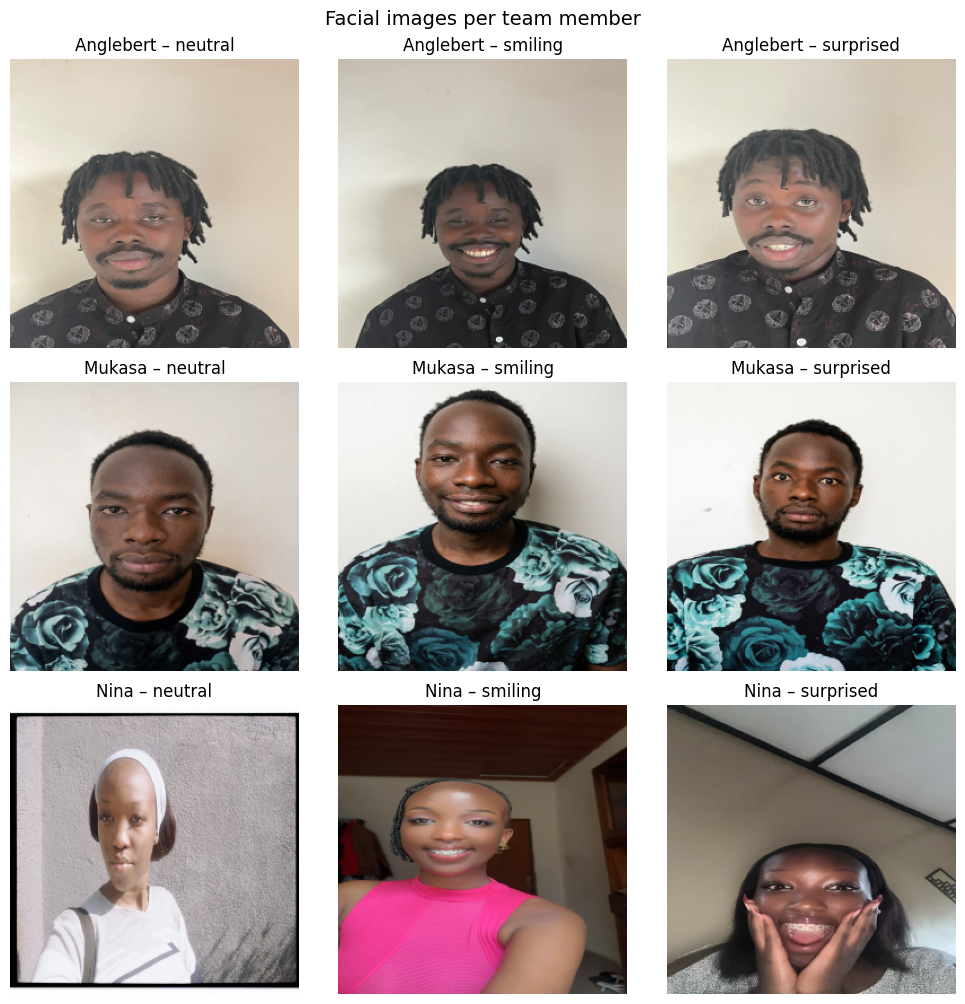

In [4]:
def display_member_grid(images):
    n = len(images)
    fig, axes = plt.subplots(n, 3, figsize=(10, 3.4 * n), squeeze=False)
    for row, (member, exps) in enumerate(images.items()):
        for col, exp in enumerate(EXPRESSIONS):
            ax = axes[row][col]
            if exp in exps:
                ax.imshow(exps[exp])
            else:
                ax.text(0.5, 0.5, "missing", ha="center", va="center")
            ax.set_title(f"{member} – {exp}")
            ax.axis("off")
    plt.suptitle("Facial images per team member", fontsize=14)
    plt.tight_layout()
    plt.show()


display_member_grid(images)

In [5]:
AUG_DIR = "augmented_images"


def flip_horizontal(image):
    return cv2.flip(image, 1)


def rotate(image, angle=15):
    h, w = image.shape[:2]
    matrix = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
    # BORDER_REFLECT avoids black corners after rotation
    return cv2.warpAffine(image, matrix, (w, h), borderMode=cv2.BORDER_REFLECT)


def to_grayscale(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    # Keep 3 channels so every image has the same shape for feature extraction
    return cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)


def adjust_brightness(image, alpha=1.2, beta=30):
    """alpha = contrast multiplier, beta = brightness offset."""
    return cv2.convertScaleAbs(image, alpha=alpha, beta=beta)


AUGMENTATIONS = {
    "flipped": flip_horizontal,
    "rotated": rotate,
    "grayscale": to_grayscale,
    "bright": adjust_brightness,
}

In [6]:
def augment_all(images):
    """Return {member: {expression: {aug_name: image}}}, including the original."""
    augmented = {}
    for member, exps in images.items():
        member_dir = os.path.join(AUG_DIR, member)
        os.makedirs(member_dir, exist_ok=True)
        augmented[member] = {}

        for exp, img in exps.items():
            versions = {"original": img}
            for aug_name, fn in AUGMENTATIONS.items():
                versions[aug_name] = fn(img)

            for aug_name, aug_img in versions.items():
                if aug_name == "original":
                    continue
                out_path = os.path.join(member_dir, f"{exp}_{aug_name}.jpg")
                cv2.imwrite(out_path, cv2.cvtColor(aug_img, cv2.COLOR_RGB2BGR))

            augmented[member][exp] = versions
    return augmented


augmented = augment_all(images)

total = sum(len(v) for exps in augmented.values() for v in exps.values())
print(f"Total images (originals + augmented): {total}")
print(f"Saved augmented files: {sum(len(f) for _, _, f in os.walk(AUG_DIR))}")

Total images (originals + augmented): 45
Saved augmented files: 36


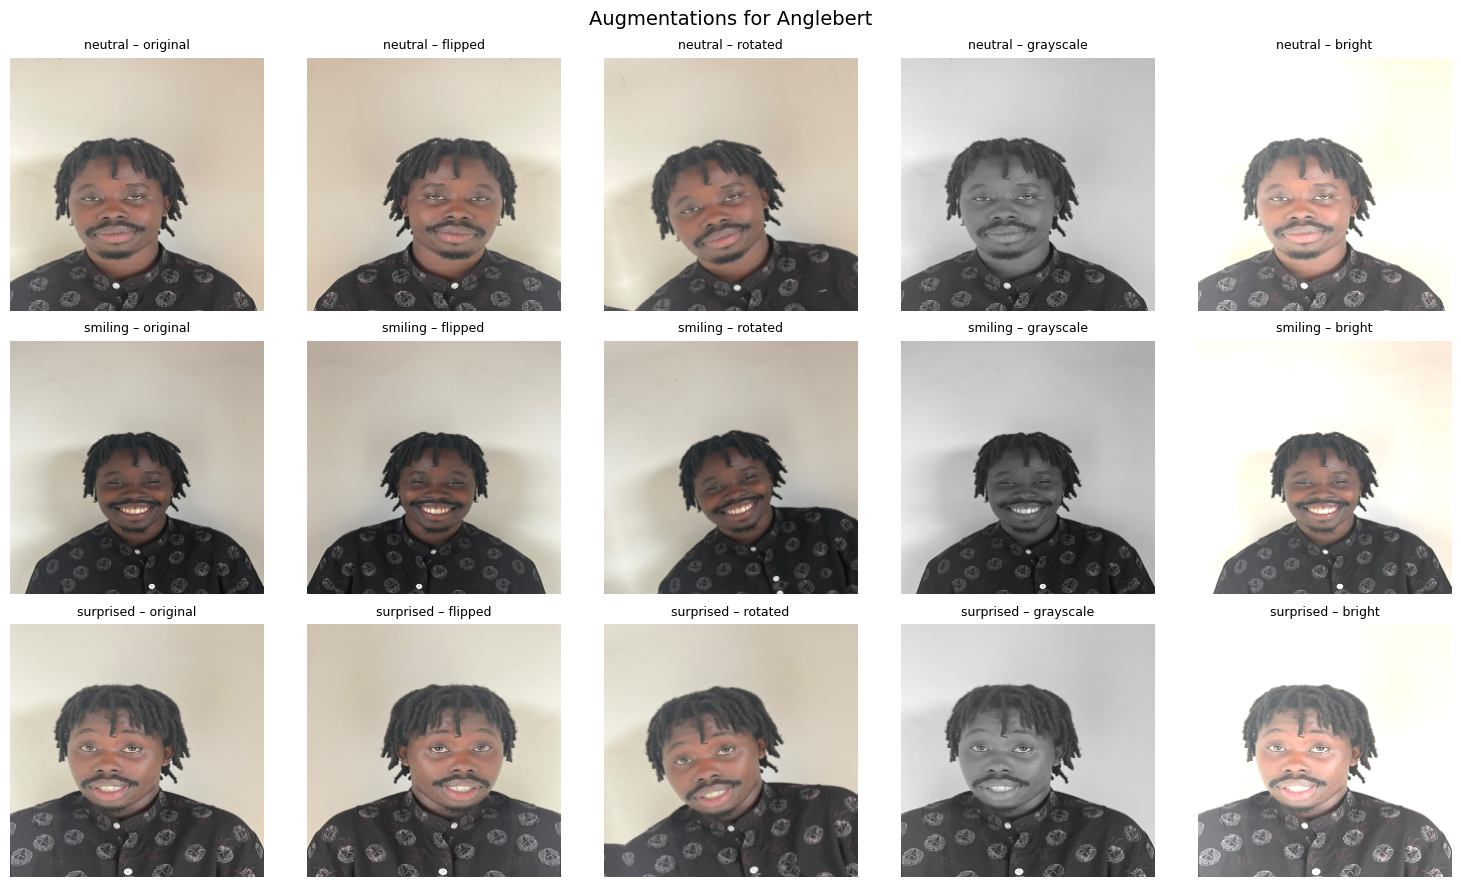

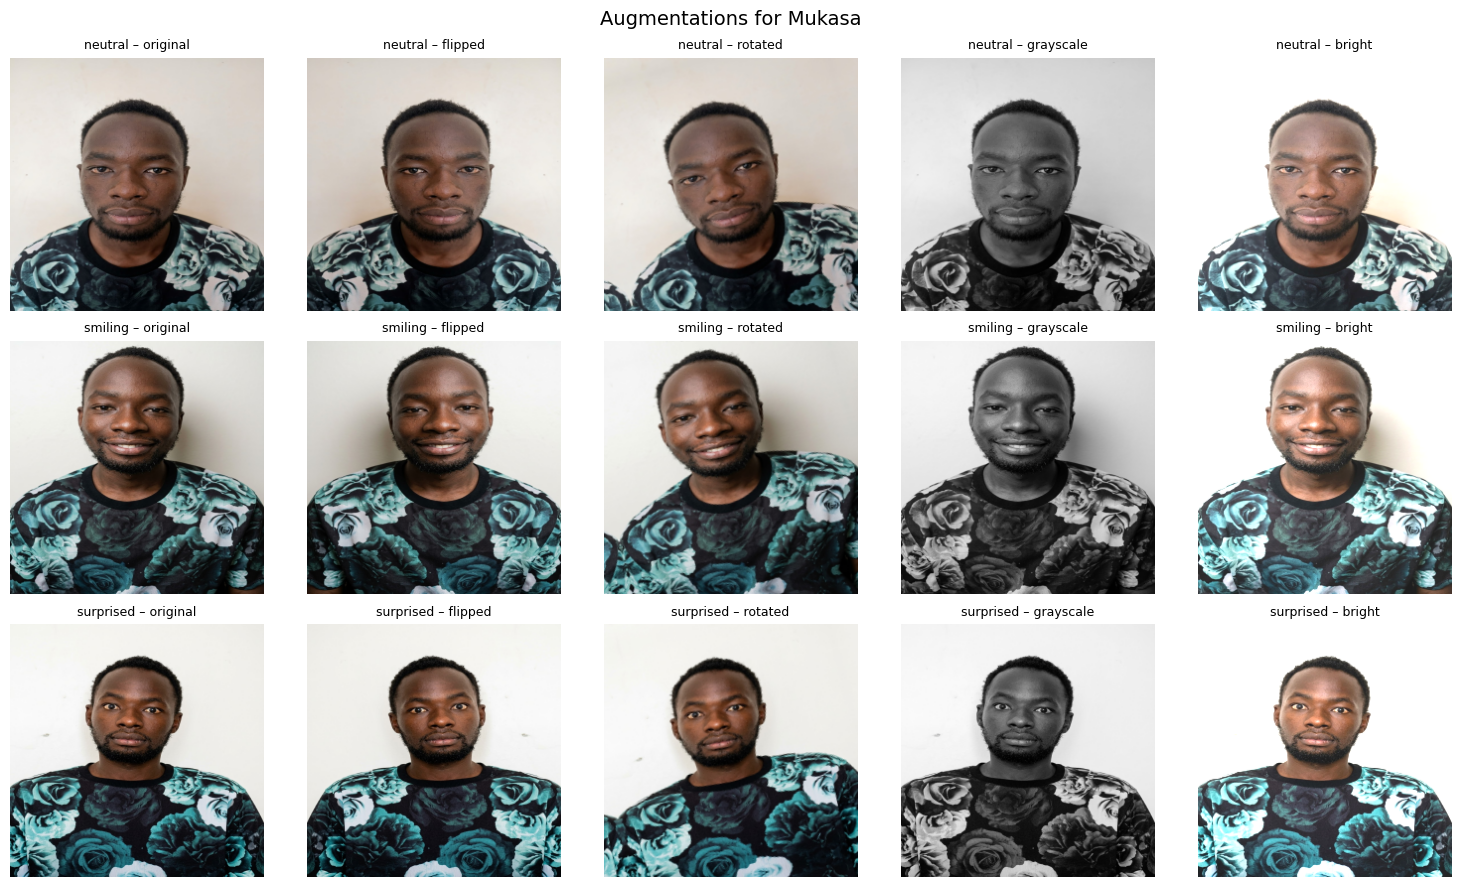

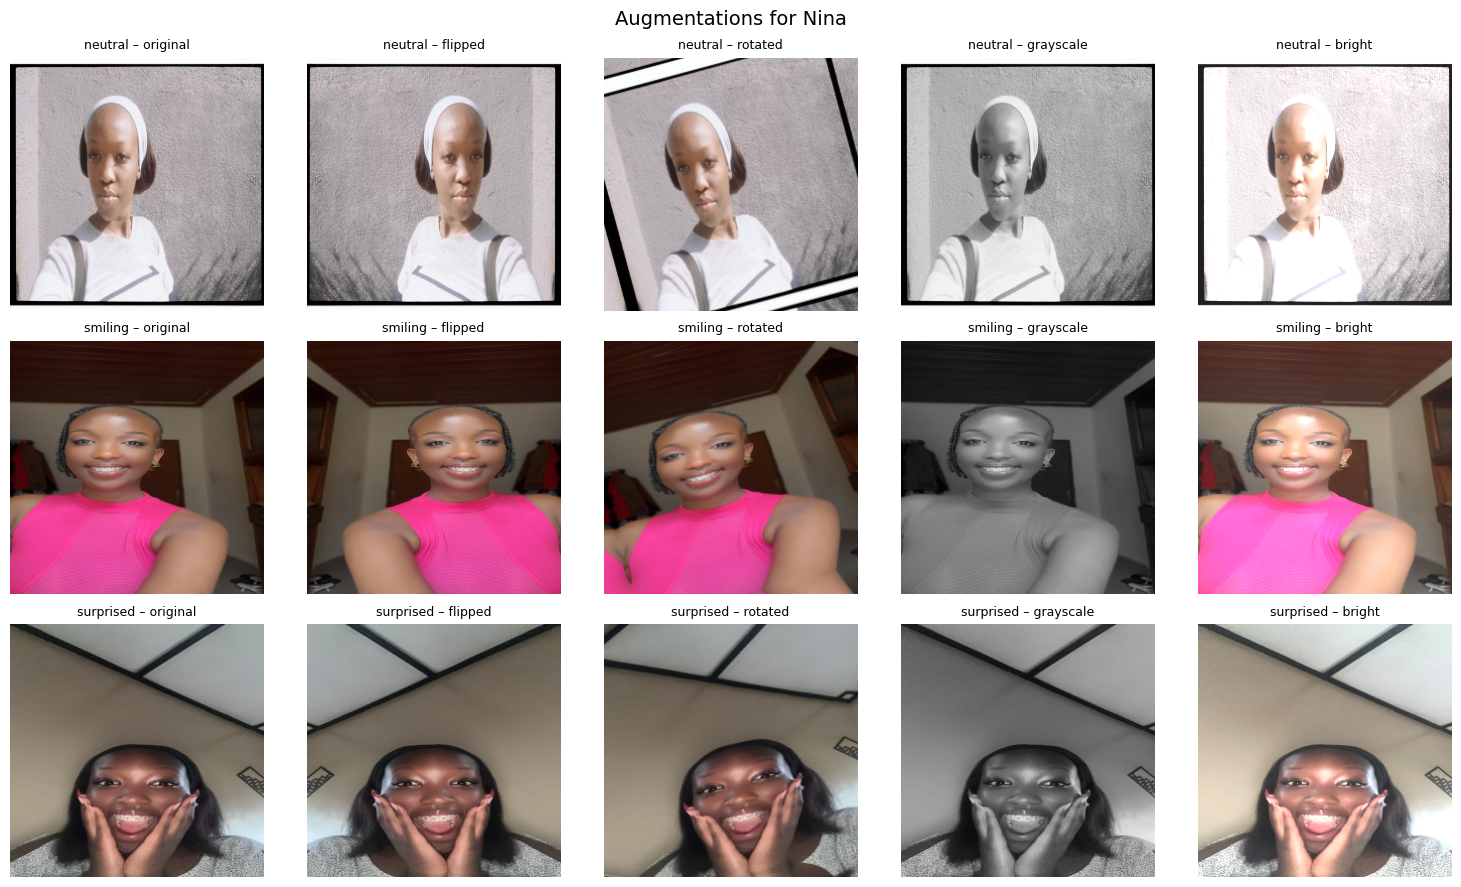

In [7]:
def display_augmentations(augmented, member):
    versions = ["original"] + list(AUGMENTATIONS.keys())
    fig, axes = plt.subplots(3, len(versions), figsize=(3 * len(versions), 9))
    for row, exp in enumerate(EXPRESSIONS):
        for col, aug_name in enumerate(versions):
            ax = axes[row][col]
            ax.imshow(augmented[member][exp][aug_name])
            ax.set_title(f"{exp} – {aug_name}", fontsize=9)
            ax.axis("off")
    plt.suptitle(f"Augmentations for {member}", fontsize=14)
    plt.tight_layout()
    plt.show()


for member in augmented:
    display_augmentations(augmented, member)

In [8]:


FACE_SIZE = (128, 128)
OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)


def detect_face(image):
    """Return the largest face box (x, y, w, h), or None if no face is found."""
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
    if len(faces) == 0:
        return None
    return max(faces, key=lambda f: f[2] * f[3])


def center_box(image, ratio=0.7):
    """Fallback box: the central 70% of the image."""
    h, w = image.shape[:2]
    bw, bh = int(w * ratio), int(h * ratio)
    return ((w - bw) // 2, (h - bh) // 2, bw, bh)


def crop_face(image, box):
    x, y, w, h = box
    return cv2.resize(image[y:y + h, x:x + w], FACE_SIZE, interpolation=cv2.INTER_AREA)

In [9]:
def intensity_stats(face):
    gray = cv2.cvtColor(face, cv2.COLOR_RGB2GRAY)
    return {
        "mean": float(gray.mean()),
        "std": float(gray.std()),
        "min": int(gray.min()),
        "max": int(gray.max()),
    }


def color_histogram(face, bins=16):
    feats = {}
    for i, ch in enumerate(["r", "g", "b"]):
        hist = cv2.calcHist([face], [i], None, [bins], [0, 256]).flatten()
        hist /= hist.sum()  # normalise so image size doesn't matter
        feats.update({f"hist_{ch}_{j}": float(v) for j, v in enumerate(hist)})
    return feats


def lbp_histogram(face, bins=32):
    """Local Binary Pattern: compares each pixel with its 8 neighbours."""
    gray = cv2.cvtColor(face, cv2.COLOR_RGB2GRAY).astype(np.int16)
    center = gray[1:-1, 1:-1]
    codes = np.zeros_like(center, dtype=np.uint8)
    neighbours = [(-1, -1), (-1, 0), (-1, 1), (0, 1), (1, 1), (1, 0), (1, -1), (0, -1)]
    for bit, (dy, dx) in enumerate(neighbours):
        neighbour = gray[1 + dy:gray.shape[0] - 1 + dy, 1 + dx:gray.shape[1] - 1 + dx]
        codes |= ((neighbour >= center).astype(np.uint8) << bit)
    hist, _ = np.histogram(codes, bins=bins, range=(0, 256))
    hist = hist / hist.sum()
    return {f"lbp_{i}": float(v) for i, v in enumerate(hist)}


hog = cv2.HOGDescriptor(
    _winSize=(64, 64), _blockSize=(16, 16), _blockStride=(16, 16),
    _cellSize=(8, 8), _nbins=9,
)


def hog_features(face):
    gray = cv2.cvtColor(cv2.resize(face, (64, 64)), cv2.COLOR_RGB2GRAY)
    vec = hog.compute(gray).flatten()
    return {f"hog_{i}": float(v) for i, v in enumerate(vec)}


def extract_features(face):
    feats = {}
    feats.update(intensity_stats(face))
    feats.update(color_histogram(face))
    feats.update(lbp_histogram(face))
    feats.update(hog_features(face))
    return feats

In [10]:
rows, crops = [], {}

for member, exps in augmented.items():
    for exp, versions in exps.items():
        # Detect on the original first; augmented versions fall back to this box
        orig_box = detect_face(versions["original"])
        orig_detected = orig_box is not None
        if orig_box is None:
            orig_box = center_box(versions["original"])

        for aug_name, img in versions.items():
            box = detect_face(img)
            detected = box is not None
            if box is None:
                x, y, w, h = orig_box
                # A flipped image needs the box mirrored horizontally
                box = (img.shape[1] - x - w, y, w, h) if aug_name == "flipped" else orig_box

            face = crop_face(img, box)
            crops[(member, exp, aug_name)] = face

            row = {
                "member_id": member,
                "expression": exp,
                "augmentation": aug_name,
                "face_detected": detected,
            }
            row.update(extract_features(face))
            rows.append(row)

features_df = pd.DataFrame(rows)
csv_path = os.path.join(OUTPUT_DIR, "image_features.csv")
features_df.to_csv(csv_path, index=False)

print(f"Saved {csv_path}: {features_df.shape[0]} rows × {features_df.shape[1]} columns")
print(f"Faces detected directly: {features_df['face_detected'].sum()}/{len(features_df)}")

Saved output/image_features.csv: 45 rows × 664 columns
Faces detected directly: 23/45


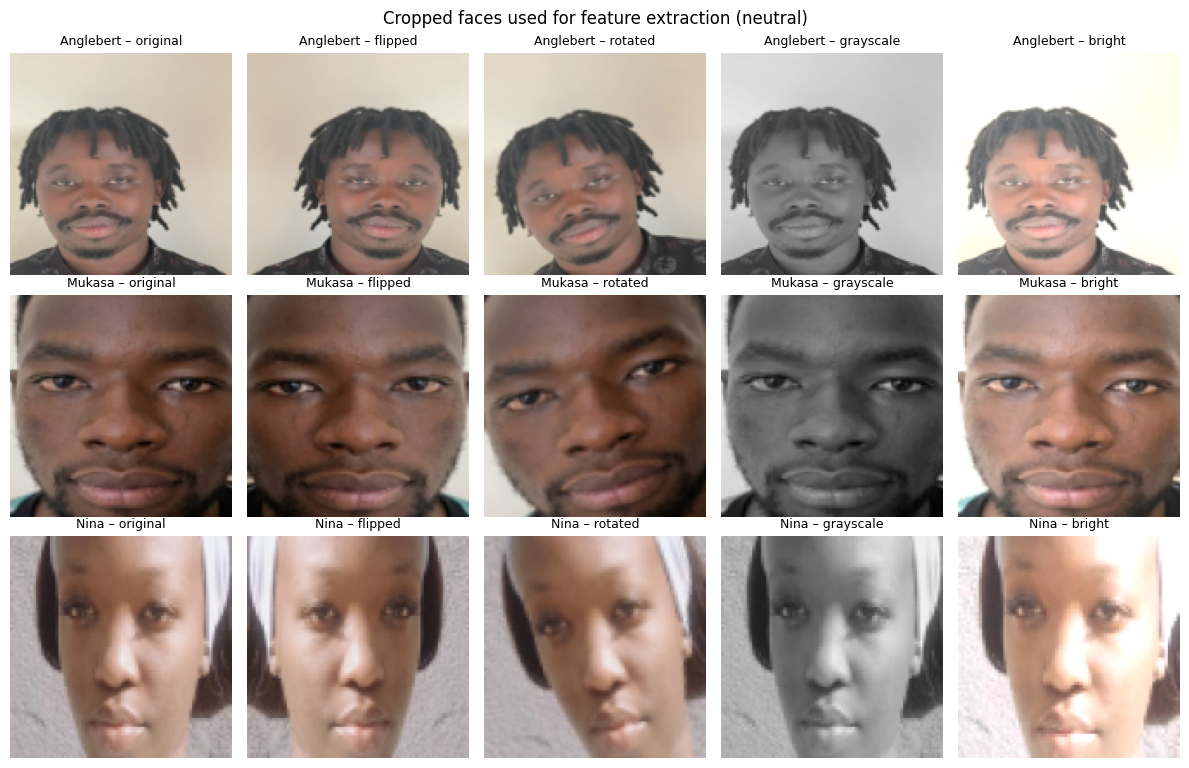

Nulls: 0
augmentation  bright  flipped  grayscale  original  rotated
member_id                                                  
Anglebert          3        3          3         3        3
Mukasa             3        3          3         3        3
Nina               3        3          3         3        3


,member_id,expression,augmentation,mean,std,min,max
0,Anglebert,neutral,original,154.305115,57.285532,25,233
1,Anglebert,neutral,flipped,154.305115,57.285532,25,233
2,Anglebert,neutral,rotated,154.235413,57.600444,25,231
3,Anglebert,neutral,grayscale,154.306580,57.287252,25,233
4,Anglebert,neutral,bright,203.928345,58.409519,60,255
5,Anglebert,smiling,original,140.992615,68.039932,16,234
6,Anglebert,smiling,flipped,140.992615,68.039932,16,234
7,Anglebert,smiling,rotated,142.280151,67.940798,17,233
8,Anglebert,smiling,grayscale,140.992920,68.035966,16,234
9,Anglebert,smiling,bright,192.684143,75.961773,49,255


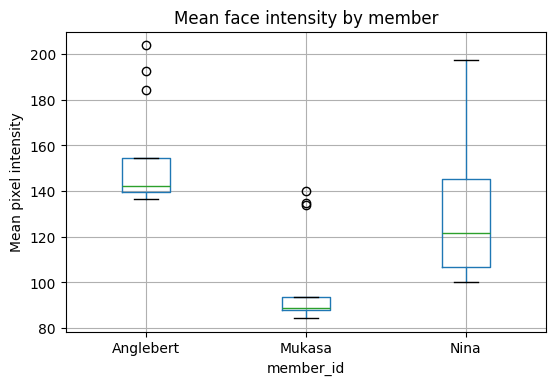

In [11]:
# 1. Faces were cropped correctly
fig, axes = plt.subplots(len(augmented), 5, figsize=(12, 2.6 * len(augmented)), squeeze=False)
for r, member in enumerate(augmented):
    for c, aug in enumerate(["original", "flipped", "rotated", "grayscale", "bright"]):
        axes[r][c].imshow(crops[(member, "neutral", aug)])
        axes[r][c].set_title(f"{member} – {aug}", fontsize=9)
        axes[r][c].axis("off")
plt.suptitle("Cropped faces used for feature extraction (neutral)")
plt.tight_layout()
plt.show()

# 2. CSV quality
print("Nulls:", features_df.isnull().sum().sum())
print(features_df.groupby(["member_id", "augmentation"]).size().unstack())
display(features_df[["member_id", "expression", "augmentation", "mean", "std", "min", "max"]].head(10))

# 3. Do the features separate members?
features_df.boxplot(column="mean", by="member_id", figsize=(6, 4))
plt.title("Mean face intensity by member")
plt.suptitle("")
plt.ylabel("Mean pixel intensity")
plt.show()